In [1]:
%gui asyncio

In [2]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from clustering.utils import SpaceTimeSVD

from tqdm import tqdm
import pygpcca

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
import tifffile

In [5]:
movie = tifffile.imread("/home/kushal/lab/datasets/drg/drg1.tif").astype(np.float32)

In [6]:
movie.shape

(6800, 293, 293)

In [7]:
%matplotlib inline

In [8]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
iw_movie.show()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [9]:
iw_movie.window_funcs = {"t": (np.mean, 7)}

In [10]:
iw = fpl.ImageWidget(movie.std(axis=0), cmap="gnuplot2", figure_kwargs={"canvas": "glfw"})
rs = iw.managed_graphics[0].add_rectangle_selector()
iw.show()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [11]:
rs.selection = (30, 145, 46, 159)

In [26]:
from ipywidgets import HBox

In [53]:
rows, cols = rs.get_selected_indices()
sub_raw = movie[:, rows[0]:rows[-1]:2, cols[0]:cols[-1]:2]
iw_movie = fpl.ImageWidget(sub_raw, cmap="gnuplot2", figure_kwargs={"size": (520, 600)})

selector1 = iw_movie.managed_graphics[0].add_rectangle_selector(name="cell-1")
selector2 = iw_movie.managed_graphics[0].add_rectangle_selector(name="cell-2")

fig_traces = fpl.Figure(size=(900, 600))

cell1 = fig_traces[0, 0].add_line(np.zeros(sub_raw.shape[0]), name="cell-1")
cell2 = fig_traces[0, 0].add_line(np.zeros(sub_raw.shape[0]), name="cell-2")

def cell_selection_changed(ev):
    rows, cols = ev.get_selected_indices()
    data = sub_raw[:, rows[0]:rows[-1], cols[0]:cols[-1]].mean(axis=(1, 2))
    data -= data.min()
    data /= data.max()
    fig_traces[0, 0][ev.graphic.name].data[:, 1] = data
    fig_traces[0, 0].auto_scale()

selector1.add_event_handler(cell_selection_changed, "selection")
selector2.add_event_handler(cell_selection_changed, "selection")

HBox([iw_movie.show(), fig_traces.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [57]:
iw_movie.window_funcs = {"t": (np.mean, 7)}

In [54]:
cell1_g = fig_traces[0, 0].add_line(np.zeros(sub_raw.shape[0]), colors=cell1.colors, name="cell-1-g")
cell2_g = fig_traces[0, 0].add_line(np.zeros(sub_raw.shape[0]), colors=cell2.colors, name="cell-2-g")

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


In [66]:
cell1_g.thickness = 10
cell2_g.thickness = 10

In [55]:
from scipy.ndimage import gaussian_filter1d

In [286]:
sigma = 8
order = 1
radius = None
truncate = 4.0

data = gaussian_filter1d(cell1.data[:, 1], sigma=sigma, order=order, radius=radius, truncate=truncate)
data -= data.min()
data /= data.max()
cell1_g.data[:, 1] = data

data = gaussian_filter1d(cell2.data[:, 1], sigma=sigma, order=order, radius=radius, truncate=truncate)
data -= data.min()
data /= data.max()
cell2_g.data[:, 1] = data

In [39]:
selector_time = fig_traces[0, 0]["cell-1"].add_linear_selector()

In [40]:
@selector_time.add_event_handler("selection")
def update_time(ev):
    i = ev.get_selected_index()
    iw_movie.current_index = {"t": i}

In [56]:
fig_traces[0, 0]["cell-1"].colors = (1., 0., 1., 0.2)
fig_traces[0, 0]["cell-2"].colors = (0., 1., 1., 0.2)

In [14]:
iw_movie.cmap = "viridis"

In [205]:
def derivative(window, axis=None, **kwargs):
    filtered = gaussian_filter1d(window, sigma=3, axis=0)
    d1 = np.abs(np.gradient(filtered, axis=0))
    ix = int((window.shape[0] - 1) / 2)
    return d1[ix]

In [206]:
iw_movie.window_funcs = None

In [207]:
iw_movie.window_funcs = {"t": (derivative, 23)}

In [12]:
tuple(rs.selection.astype(int).tolist())

(30, 145, 46, 159)

In [15]:
sub_raw.shape

(6800, 56, 57)

In [311]:
sub = sub_raw
Y = sub.reshape(sub.shape[0], sub.shape[1] * sub.shape[2]).T.astype(np.float64)
Y.shape

(3192, 6800)

In [312]:
gfiltered = gaussian_filter1d(Y, sigma=8, axis=1, order=1)
# Yd = np.abs(np.gradient(gfiltered, axis=1))
Y = gfiltered

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
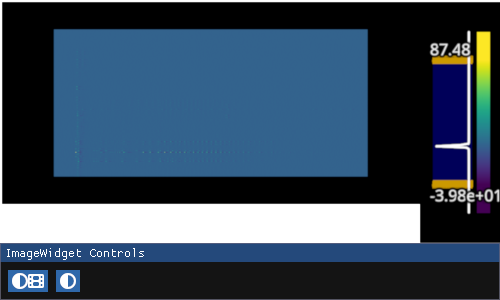

In [313]:
fpl.ImageWidget(Y, cmap="viridis").show()

In [314]:
from sklearn.metrics import pairwise_distances

In [413]:
B = pairwise_distances(Y, Y, n_jobs=14, metric="euclidean")

RFBOutputContext()

JupyterWgpuCanvas()
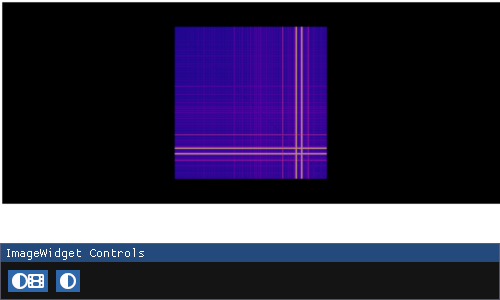

In [414]:
fpl.ImageWidget(B, histogram_widget=False).show()

In [418]:
B.min(), B.max()

(np.float64(0.0), np.float64(1320.335653094329))

In [415]:
d = 1.0 / np.sum(B.astype(np.float64), axis=1)

In [416]:
A = np.diag(d) @ B

In [417]:
A.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

RFBOutputContext()

JupyterWgpuCanvas()
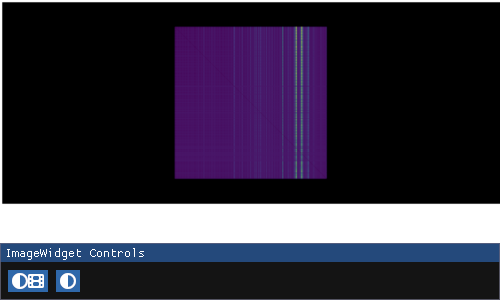

In [419]:
iw_s = fpl.ImageWidget(A, cmap="viridis", histogram_widget=False)
iw_s.show()

In [420]:
A.min(), A.max()

(np.float64(0.0), np.float64(0.005235386103679766))

In [421]:
np.sum(A[0, :])

np.float64(0.9999999999999981)

In [422]:
A.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [423]:
import pygpcca as gp

In [424]:
gpcca = gp.GPCCA(A, z="LM", method="brandts")

In [425]:
mc = gpcca.minChi(10, 20)

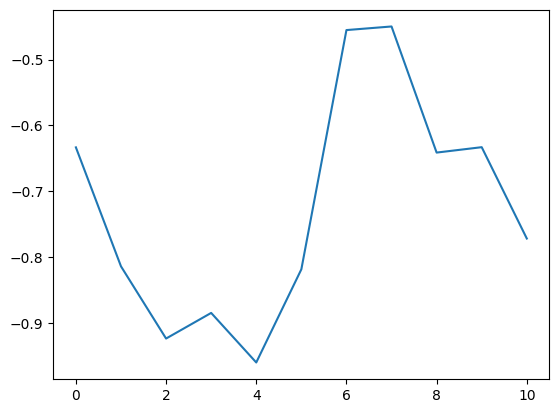

In [426]:
plt.plot(mc)

In [427]:
mc

[np.float64(-0.6334228845750255),
 np.float64(-0.8141383572167262),
 np.float64(-0.9238021624075855),
 np.float64(-0.8848773348531048),
 np.float64(-0.9601515089718614),
 np.float64(-0.8186685092004587),
 np.float64(-0.4552940053704855),
 np.float64(-0.44982963031191653),
 np.float64(-0.6413597425341062),
 np.float64(-0.633156546581796),
 np.float64(-0.7718860725352328)]

In [428]:
np.argmax(mc)

np.int64(7)

In [429]:
%%time
gpcca.optimize(17)

CPU times: user 17.9 s, sys: 69 ms, total: 18 s
Wall time: 18 s


GPCCA[n=3192, n_macrostates=17]

In [430]:
gpcca.memberships.shape

(3192, 17)

In [431]:
gpcca.crispness_values

array([0.08475379])

In [432]:
labels = gpcca.memberships.reshape(sub.shape[1], sub.shape[2], gpcca.memberships.shape[-1])

In [433]:
from ipywidgets import HBox

In [434]:
from fastplotlib.ui import EdgeWindow
from imgui_bundle import imgui

In [435]:
fig_comps = fpl.Figure(canvas="glfw")

ix = 0
for i in range(7):
    for j in range(3):
        if ix > labels.shape[-1] - 1:
            break
        img = labels.T[ix].T
        fig_comps[0, 0].add_image(img, cmap="viridis", offset=(i * img.shape[1] + 10 * i, j * img.shape[0] + 10 * j, 0))
        ix += 1

fig_comps.show()#, iw_movie.show()

In [337]:
iw_movie.window_funcs = {"t": (np.mean, 5)}

In [338]:
for i, _ in enumerate(labels.T):
    iw.managed_graphics[i].vmin = np.percentile(labels.T[i], 90)
    iw.managed_graphics[i].vmax = labels.T[i].max()

IndexError: list index out of range

In [ ]:
from ipywidgets import VBox

In [ ]:
iw1 = fpl.ImageWidget(sub)
iw2 = fpl.ImageWidget(sub)

fig = fpl.Figure()

fig[0, 0].add_scatter(np.argwhere(labels.T[3] > 0.1), colors="g", sizes=10, alpha=0.4)
fig[0, 0].add_scatter(np.argwhere(labels.T[8] > 0.15), colors="r", sizes=10, alpha=0.4)

VBox([fig.show(), HBox([iw1.show(), iw2.show()])])

In [42]:
fig.renderer.blend_mode = "weighted_plus"

In [43]:
iw1.current_index = {"t": 2288}
iw2.current_index = {"t": 3972}

In [44]:
gpcca.coarse_grained_transition_matrix.min()

np.float64(0.020271349682074485)

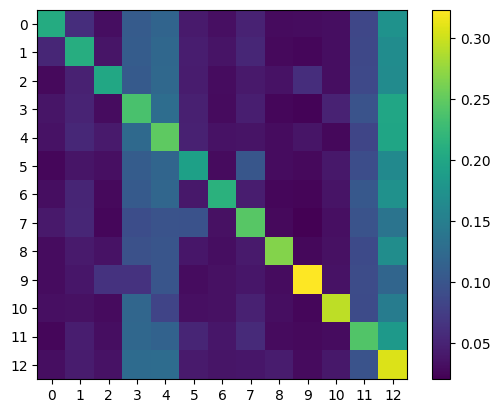

array([[0.20637425, 0.06001968, 0.03165649, 0.10761106, 0.11825953,
        0.04267813, 0.03252963, 0.049109  , 0.02971941, 0.03059786,
        0.03168177, 0.08495982, 0.17480337],
       [0.05240353, 0.20922359, 0.03782766, 0.10794889, 0.12097869,
        0.04418016, 0.03613014, 0.05282541, 0.02764983, 0.02597006,
        0.03198886, 0.08557976, 0.16729342],
       [0.02743826, 0.04856128, 0.20234833, 0.10591334, 0.12221456,
        0.04326885, 0.02993824, 0.04068926, 0.03529704, 0.05938069,
        0.03192726, 0.08707221, 0.16595067],
       [0.03696616, 0.05043668, 0.0297486 , 0.23677653, 0.12841798,
        0.04718043, 0.02904891, 0.04581267, 0.02570839, 0.02290876,
        0.04913828, 0.09801692, 0.19983969],
       [0.03528057, 0.05413678, 0.04159435, 0.12364881, 0.24827496,
        0.04760441, 0.03541237, 0.03676327, 0.03012524, 0.03776509,
        0.02658075, 0.08415478, 0.19865862],
       [0.02595015, 0.03712791, 0.03272326, 0.10847392, 0.11867696,
        0.19247629, 0.02952

In [45]:
P_c = gpcca.coarse_grained_transition_matrix
# plot P_c:
fig, ax = plt.subplots()
c = ax.imshow(P_c)
plt.xticks(np.arange(P_c.shape[1]))
plt.yticks(np.arange(P_c.shape[0]))
plt.ylim(-0.5, P_c.shape[0]-0.5)
ax.set_ylim(ax.get_ylim()[::-1])
fig.colorbar(c)
plt.show()
# show P_c matrix:
P_c

In [51]:
gpcca.coarse_grained_transition_matrix[gpcca.coarse_grained_transition_matrix < 0]

array([], dtype=float64)

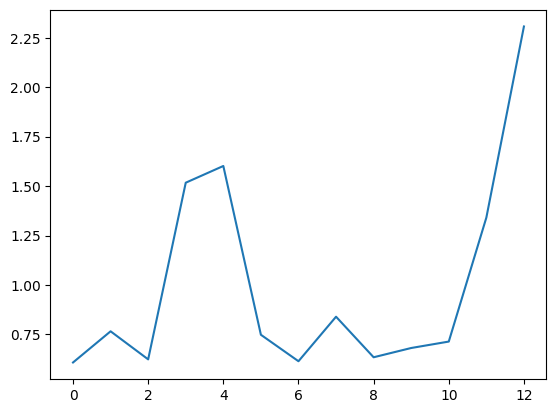

In [52]:
plt.plot(gpcca.coarse_grained_transition_matrix.sum(axis=0))